# Gaussian Process reconstruction of the Working_final_maps stadium

This GP-only notebook uses the imported `stadium_map.py` and `extract_sound_venues.py`. The stadium generator supplies **91 frames, two seconds apart**, with reflected sound. Each of 15 microphone layouts observes the same simulated sequence. A fixed 15 m RBF GP and a phone-validated GP predict the audience region independently for every frame.

The full simulated field is reserved for evaluation. All sound levels here are **synthetic, unweighted broadband dB**, not calibrated phone measurements or dBA.

## 1. Locate the project and confirm the sources

Run cells from top to bottom. The precomputed stadium output is loaded by default. Set `RUN_MODEL = True` to rebuild all 15 configurations and their figures. Rebuilding can take time because the stadium field includes reflections.

In [1]:
from pathlib import Path
import csv
import hashlib
import sys
import numpy as np
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
ROOT = next((p for p in (current, *current.parents)
             if (p / '仿真/andreib/Working_final_maps/stadium_map.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the MDM3 project.')
sys.path.insert(0, str(ROOT / '仿真/austin'))
from gp_working_final_stadium import main, OUTPUT, INPUTS, PREDICTIONS, EVALUATION, TEAM_DIR

RUN_MODEL = False
if RUN_MODEL or not (EVALUATION / 'overall_metrics.csv').exists():
    main()

def read_csv(path):
    with path.open(newline='') as handle:
        return list(csv.DictReader(handle))

sources = read_csv(OUTPUT / 'source_files.csv')
for row in sources:
    current_hash = hashlib.sha256(Path(row['path']).read_bytes()).hexdigest()
    if current_hash != row['sha256']:
        raise ValueError(f"Source changed: {row['file']}. Set RUN_MODEL = True and rerun.")
    print(f"Verified: {row['path']} | SHA-256 {row['sha256'][:16]}...")
print('Output folder:', OUTPUT)

Verified: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/stadium_map.py | SHA-256 6e1a860d2b45115a...
Verified: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/extract_sound_venues.py | SHA-256 211ddf81badf7bbe...
Verified: /Users/a603/Desktop/MDM3/仿真/andreib/Working_final_maps/single_wall.py | SHA-256 d64036025d72029f...
Output folder: /Users/a603/Desktop/MDM3/gp_working_final_stadium_output


## 2. Model and evaluation settings

The fixed model uses an RBF length scale of **15 m**. The second model tests **2, 5, 8, 15, 25, and 40 m**, selecting one by five-fold validation on held-out **microphone readings**. This choice never uses the hidden full map. The assumed GP observation noise is **0.5 dB**; it is a modeling setting, not measured phone calibration error.

The same 15 layouts (10, 30, 50, 100, or 250 microphones × random, grid, or clustered) are used for both models. Predictions have shape `(91, 17650)`: 91 independent spatial maps over the allowed audience cells.

In [2]:
settings = read_csv(PREDICTIONS / 'model_settings.csv')[0]
for key, value in settings.items():
    print(f'{key}: {value}')
truth = np.load(EVALUATION / 'true_levels.npy', mmap_mode='r')
query = np.load(INPUTS / 'query_positions.npy', mmap_mode='r')
mask = np.load(INPUTS / 'allowed_mask.npy')
print('Truth:', truth.shape, '| audience queries:', query.shape, '| mask:', mask.shape)
print('Prediction example:',
      np.load(PREDICTIONS / 'prediction_phone_cv_100_grid.npy', mmap_mode='r').shape)

kernel: RBF
fixed_length_scale_m: 15.0
cv_candidate_lengths_m: 2.0,5.0,8.0,15.0,25.0,40.0
signal_std_db: 15.0
assumed_noise_std_db: 0.5
jitter: 1e-06
frame_model: independent_spatial_GP
field: unweighted synthetic broadband SPL
evaluation_region: audience mask
display_frame: 65
display_time_seconds: 130.0
stadium_reflections: True
Truth: (91, 17650) | audience queries: (17650, 2) | mask: (176, 161)
Prediction example: (91, 17650)


## 3. Results for every configuration

**MAE** is mean absolute error, **RMSE** emphasizes larger errors, **bias** shows average over- or under-prediction, **P95** is the 95th percentile of absolute error, and **high-level MAE** is computed on the loudest 10% of audience cells in each frame. Every metric below combines **all 91 frames**, rather than just the displayed frame. The complete values are in `overall_metrics.csv`; `frame_metrics.csv` contains one row per model, layout, and frame.

In [3]:
rows = read_csv(EVALUATION / 'overall_metrics.csv')
lines = ['| Layout | Phones | GP | RMSE (dB) | MAE (dB) | High-level MAE (dB) |',
         '|:--|--:|:--|--:|--:|--:|']
for layout in ('random', 'grid', 'clustered'):
    for count in (10, 30, 50, 100, 250):
        for model in ('fixed_15m', 'phone_cv'):
            row = next(r for r in rows if r['layout'] == layout
                       and int(r['phone_count']) == count and r['model'] == model)
            lines.append(f"| {layout} | {count} | {model} | {float(row['RMSE_db']):.3f} | "
                         f"{float(row['MAE_db']):.3f} | "
                         f"{float(row['high_level_MAE_db']):.3f} |")
display(Markdown('\n'.join(lines)))

| Layout | Phones | GP | RMSE (dB) | MAE (dB) | High-level MAE (dB) |
|:--|--:|:--|--:|--:|--:|
| random | 10 | fixed_15m | 1.335 | 1.001 | 2.422 |
| random | 10 | phone_cv | 1.383 | 1.011 | 2.636 |
| random | 30 | fixed_15m | 1.368 | 1.038 | 2.409 |
| random | 30 | phone_cv | 1.401 | 1.007 | 2.982 |
| random | 50 | fixed_15m | 1.650 | 1.193 | 1.856 |
| random | 50 | phone_cv | 1.290 | 0.949 | 2.396 |
| random | 100 | fixed_15m | 1.599 | 1.090 | 1.640 |
| random | 100 | phone_cv | 1.103 | 0.798 | 1.510 |
| random | 250 | fixed_15m | 1.203 | 0.818 | 1.233 |
| random | 250 | phone_cv | 0.881 | 0.640 | 1.288 |
| grid | 10 | fixed_15m | 1.344 | 0.965 | 2.653 |
| grid | 10 | phone_cv | 1.344 | 0.965 | 2.653 |
| grid | 30 | fixed_15m | 1.317 | 1.031 | 1.728 |
| grid | 30 | phone_cv | 1.219 | 0.941 | 1.916 |
| grid | 50 | fixed_15m | 1.244 | 0.953 | 1.532 |
| grid | 50 | phone_cv | 1.130 | 0.877 | 1.656 |
| grid | 100 | fixed_15m | 1.229 | 0.887 | 1.328 |
| grid | 100 | phone_cv | 0.980 | 0.747 | 1.295 |
| grid | 250 | fixed_15m | 1.106 | 0.742 | 1.097 |
| grid | 250 | phone_cv | 0.927 | 0.733 | 1.330 |
| clustered | 10 | fixed_15m | 1.741 | 1.302 | 2.592 |
| clustered | 10 | phone_cv | 1.741 | 1.302 | 2.592 |
| clustered | 30 | fixed_15m | 2.073 | 1.450 | 2.846 |
| clustered | 30 | phone_cv | 1.545 | 1.102 | 2.765 |
| clustered | 50 | fixed_15m | 1.907 | 1.375 | 2.886 |
| clustered | 50 | phone_cv | 3.052 | 2.037 | 2.426 |
| clustered | 100 | fixed_15m | 2.298 | 1.507 | 3.030 |
| clustered | 100 | phone_cv | 4.758 | 2.554 | 3.781 |
| clustered | 250 | fixed_15m | 1.765 | 1.224 | 2.918 |
| clustered | 250 | phone_cv | 1.530 | 1.049 | 2.789 |

The phone-validated GP improves many layouts, but not all. In particular, clustered samples can have a low held-out-phone error while missing large parts of the stadium. Compare `phone_cv_scores.csv` with the full-audience metrics before concluding that a selected length scale is useful.

## 4. All 15 microphone configurations

Each panel overlays microphone positions on **frame 65 (130 s)** of the same simulated stadium field. The goal event starts at 120 s, so this chosen frame shows active celebration. The positions stay fixed across all 91 frames. This figure shows the input geometry; it is not a GP prediction.

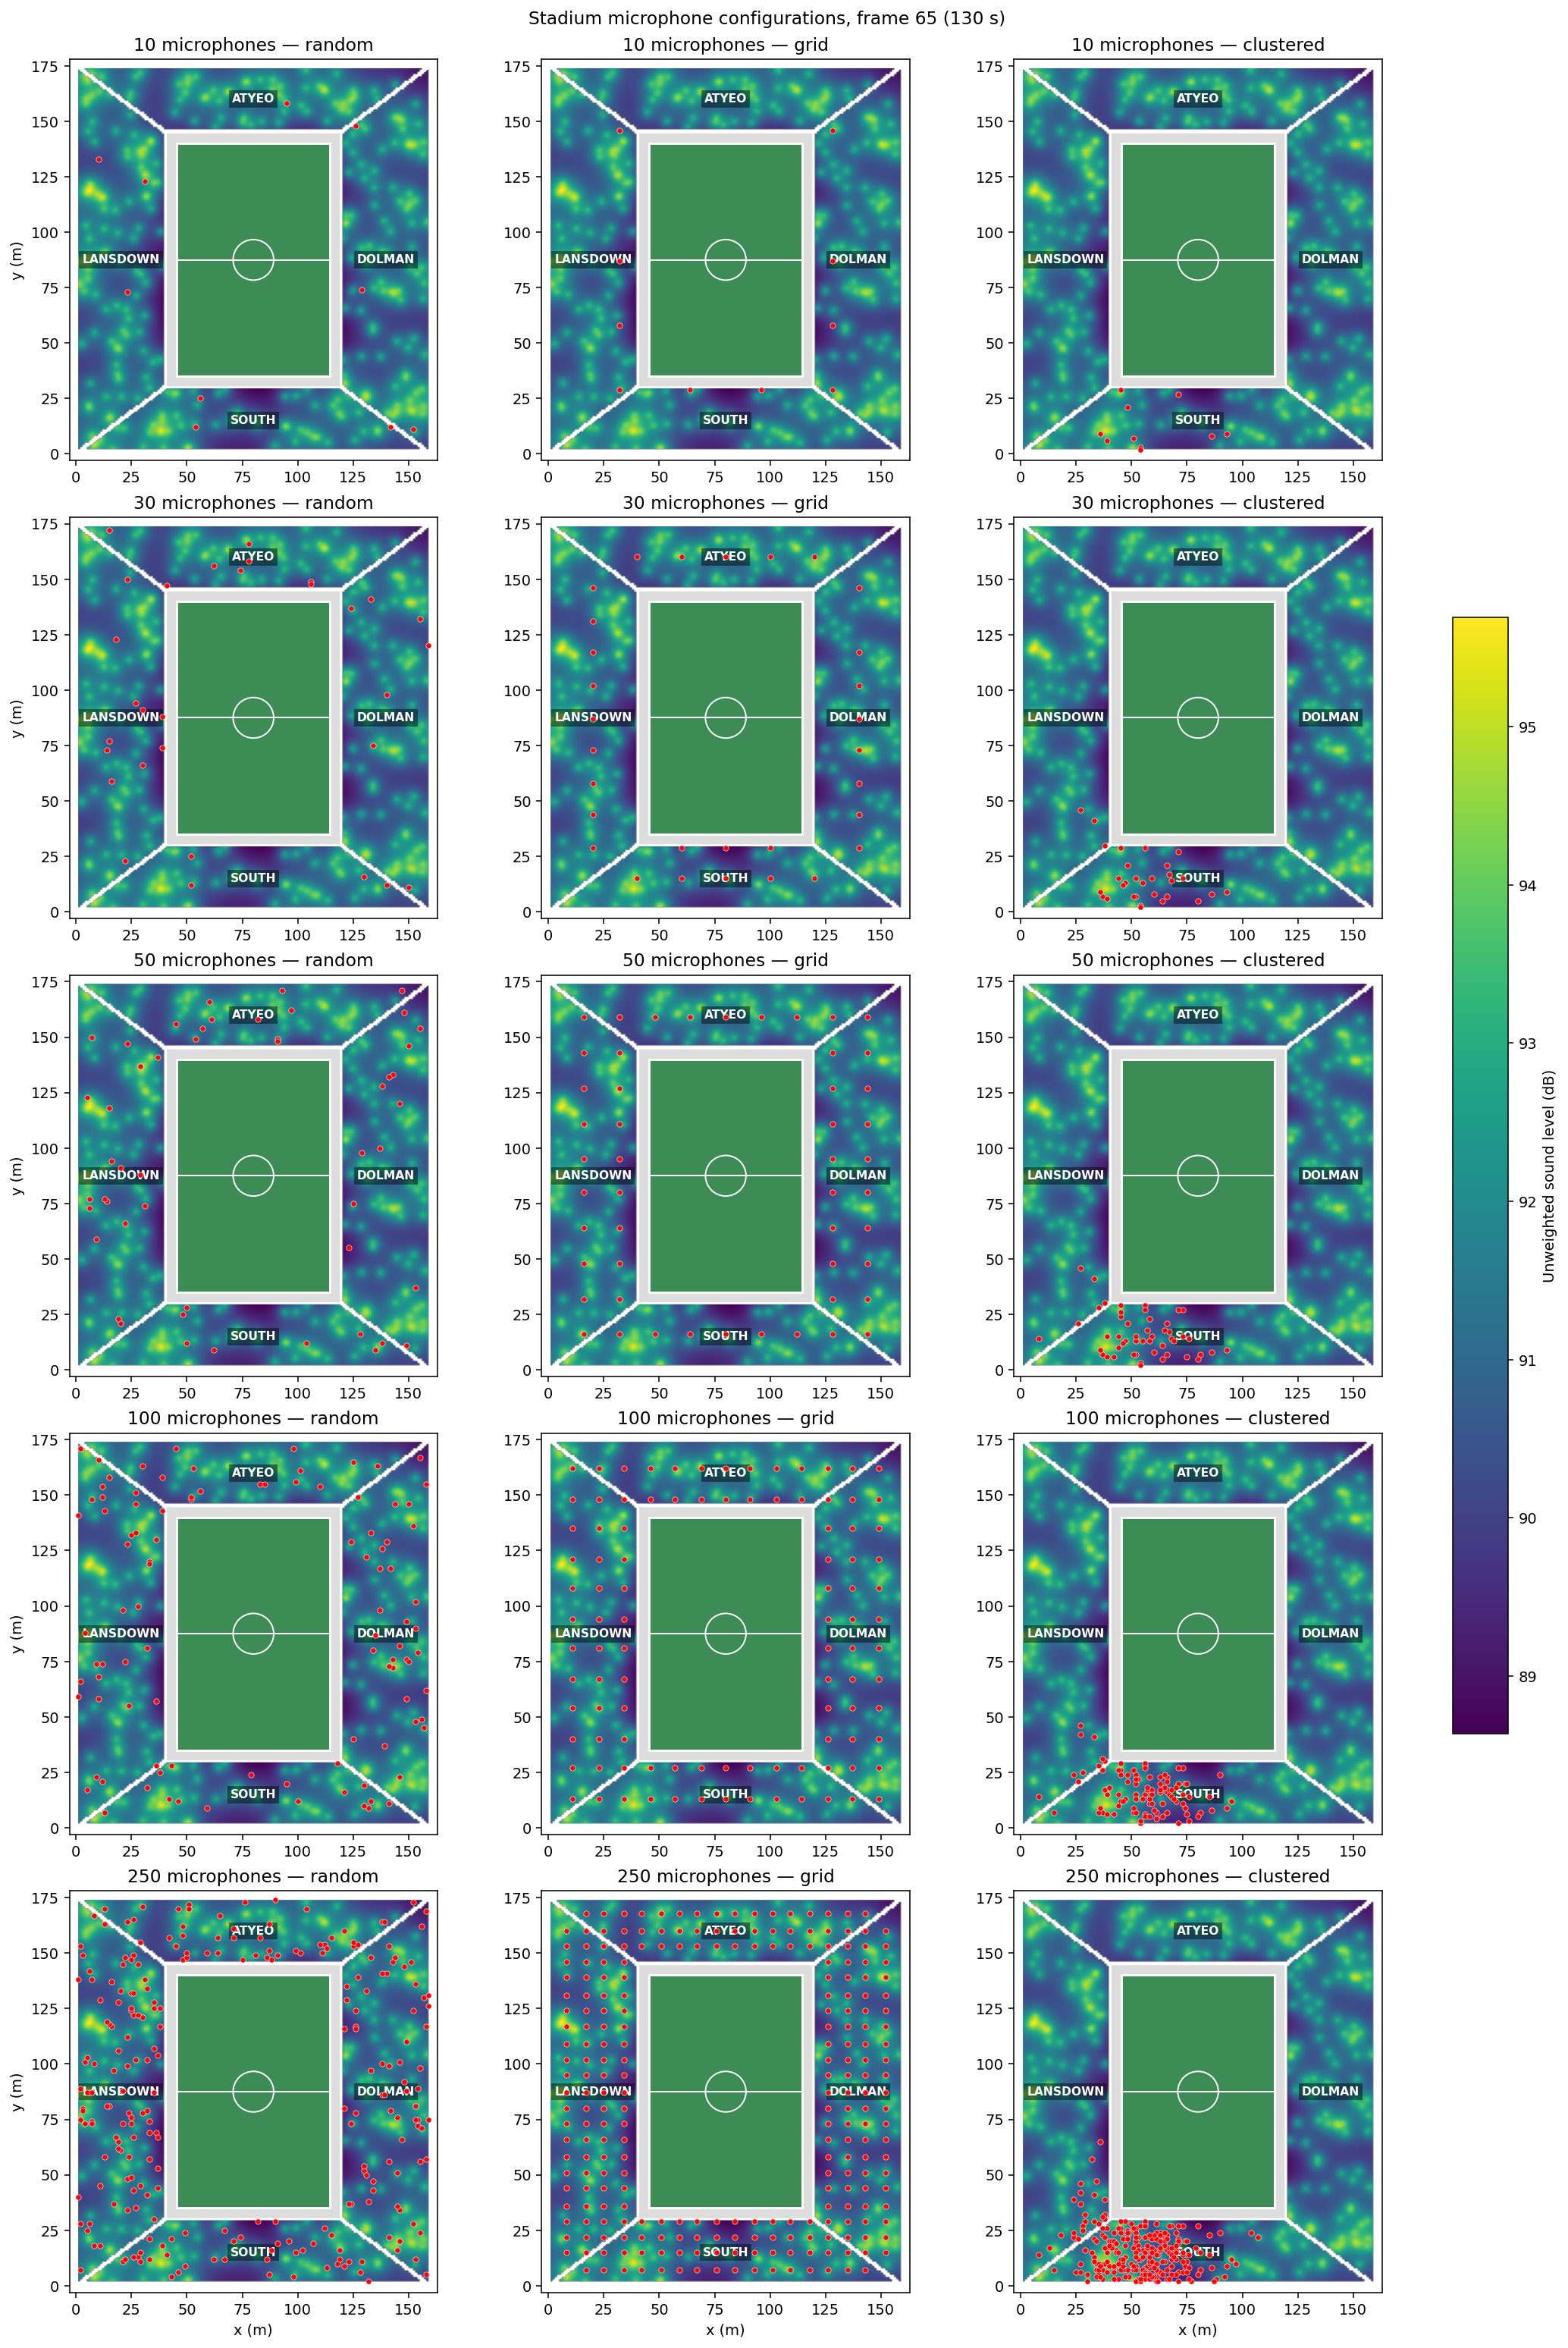

In [4]:
display(Image(filename=str(EVALUATION / 'stadium_all_microphone_configurations.png')))

## 5. True field, two GP predictions, and error

This figure uses **100 grid microphones at frame 65**. The first three panels share the same sound-level colour scale. Red dots on both predictions and the error panel show the exact measurement positions. The final panel is absolute prediction error against the hidden simulated truth, so it is available only in the simulation. The blank pitch is outside the audience evaluation mask.

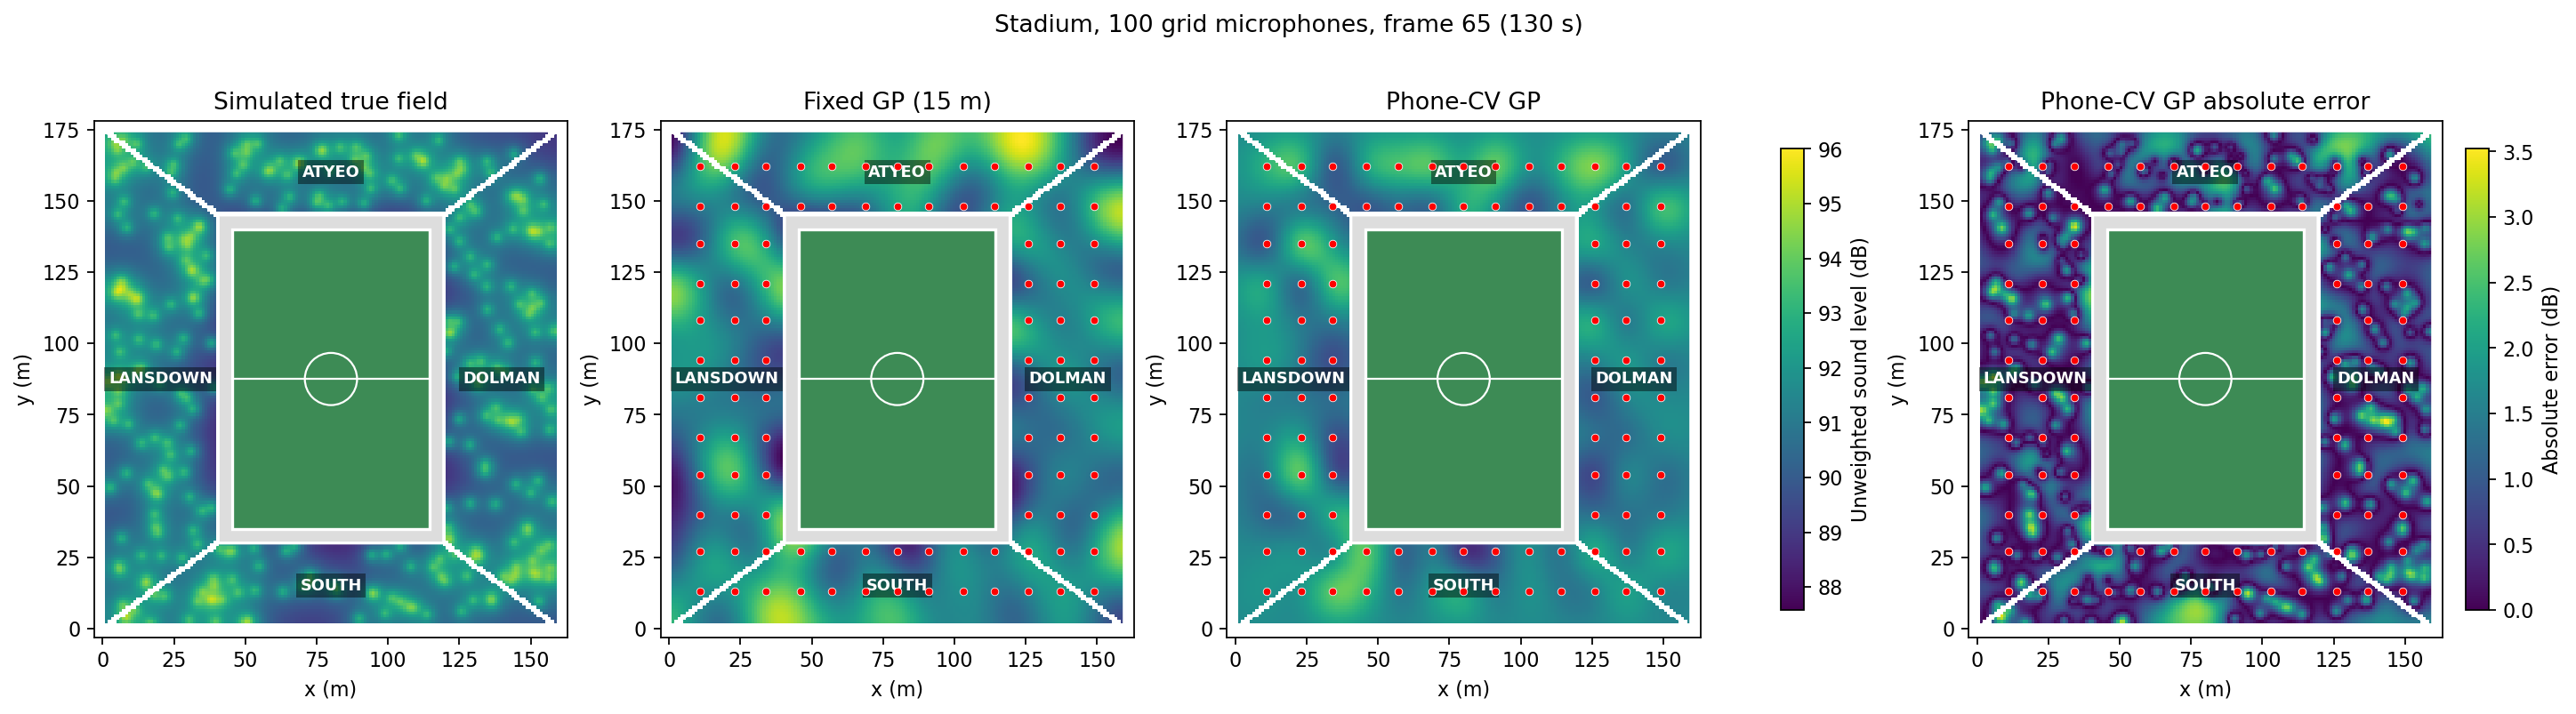

In [5]:
display(Image(filename=str(EVALUATION / 'stadium_gp_baseline_vs_tuned_100_grid.png')))

## 6. Error versus microphone count

Each panel compares fixed and phone-validated GP under one sampling layout. Its RMSE covers **every audience cell and all 91 frames**. Increasing phone count need not give a perfectly monotone curve because the sampler chooses a new configuration at each count; the sets are not necessarily nested.

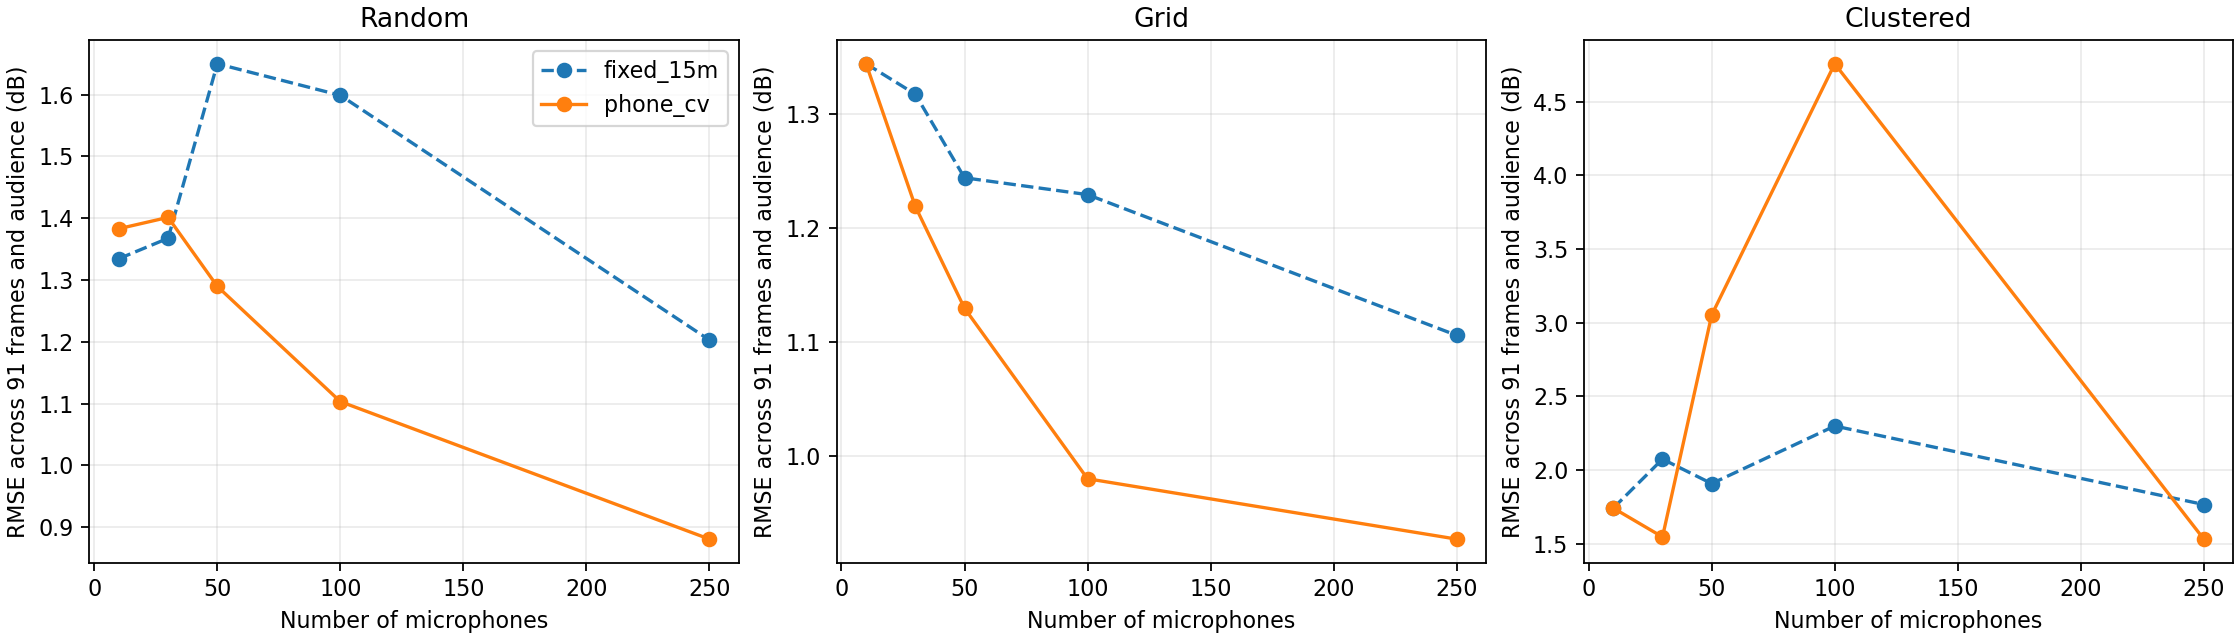

In [6]:
display(Image(filename=str(EVALUATION / 'stadium_gp_baseline_vs_tuned_rmse.png')))

## 7. Error over simulated time

For the 100-grid example, these are separate **spatial GP fits at each frame** with the same microphone locations and length scale. This is not a full space-time GP. The dotted lines mark the simulated goal onset (120 s) and displayed frame (130 s).

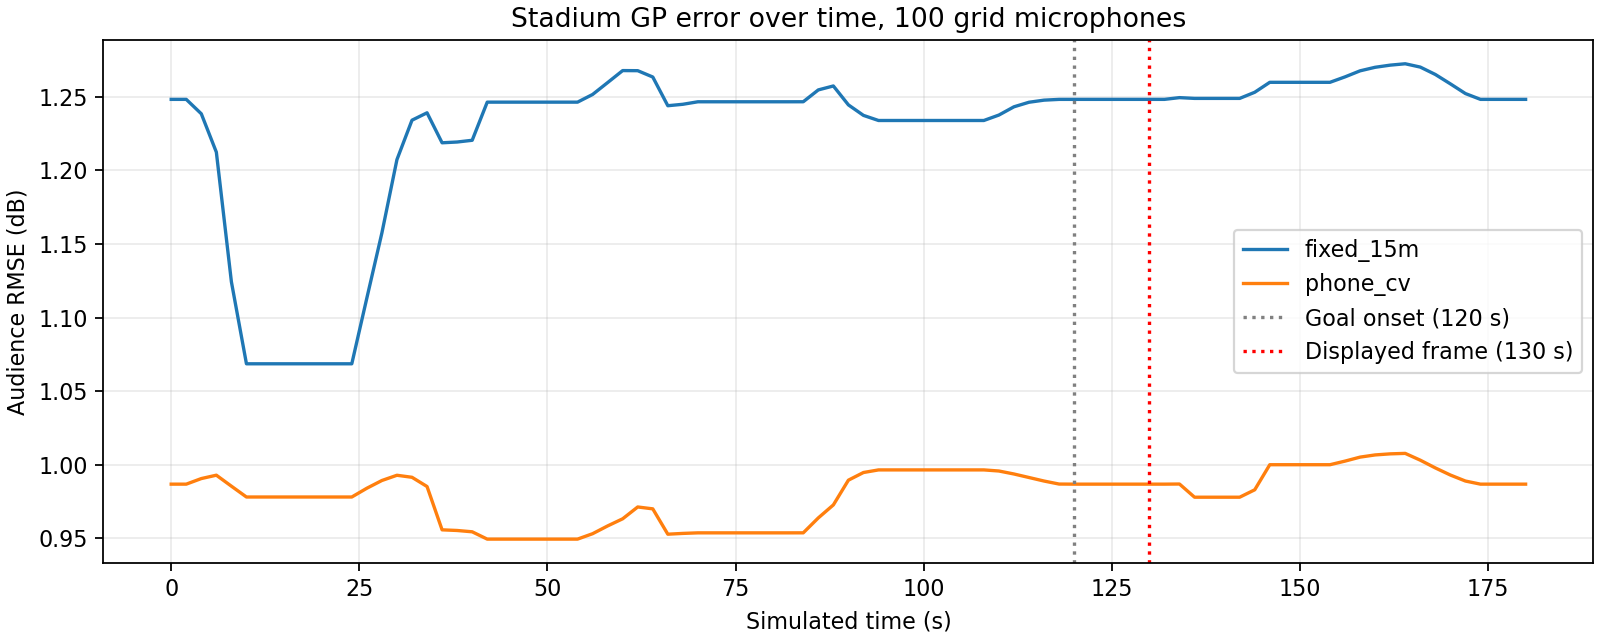

In [7]:
display(Image(filename=str(EVALUATION / 'stadium_gp_rmse_over_time_100_grid.png')))

## 8. Inspect the 100-grid length-scale choice

Phone CV predicts each held-out microphone from the others, across all 91 frames. The selected value is compared with the complete-map score above; the latter is used only to assess the finished prediction.

In [8]:
cv = [r for r in read_csv(PREDICTIONS / 'phone_cv_scores.csv')
      if r['phone_count'] == '100' and r['layout'] == 'grid']
selected = next(r for r in read_csv(PREDICTIONS / 'selected_length_scales.csv')
                if r['phone_count'] == '100' and r['layout'] == 'grid')
lines = ['| Candidate length scale (m) | Held-out phone RMSE (dB) |',
         '|--:|--:|']
for row in cv:
    lines.append(f"| {float(row['length_scale_m']):g} | "
                 f"{float(row['phone_cv_RMSE_db']):.3f} |")
display(Markdown('\n'.join(lines)))
print('Selected length scale:', selected['selected_length_scale_m'], 'm')

Selected length scale: 8.0 m


| Candidate length scale (m) | Held-out phone RMSE (dB) |
|--:|--:|
| 2 | 1.453 |
| 5 | 1.373 |
| 8 | 1.200 |
| 15 | 1.869 |
| 25 | 1.564 |
| 40 | 1.352 |

## 9. Saved data and interpretation limits

- `source_files.csv` stores the exact imported source paths and hashes.
- `model_inputs/` stores the common audience coordinates, mask, and all 15 phone observation arrays.
- `gp_predictions/` stores all 30 predicted sequences, phone-validation scores, selected lengths, and settings.
- `evaluation_only/` stores the simulated truth, overall and frame-level metrics, and figures.

The GP estimates sound level from sampled positions. It does not solve the acoustic propagation model itself, and its error map is not a GP uncertainty map. Results are for this synthetic stadium and these chosen layouts, not a claim about real phone accuracy.

In [9]:
manifest = read_csv(OUTPUT / 'run_manifest.csv')
print('Configurations:', len(manifest))
print('Frame-level metric rows:', len(read_csv(EVALUATION / 'frame_metrics.csv')))
print('Saved figures:')
for path in sorted(EVALUATION.glob('*.png')):
    print(' -', path.name)
print('To rebuild everything, set RUN_MODEL = True in section 1 and run all cells.')

Configurations: 30
Frame-level metric rows: 2730
Saved figures:
 - stadium_all_microphone_configurations.png
 - stadium_gp_baseline_vs_tuned_100_grid.png
 - stadium_gp_baseline_vs_tuned_rmse.png
 - stadium_gp_rmse_over_time_100_grid.png
To rebuild everything, set RUN_MODEL = True in section 1 and run all cells.
